## Final Project


### Scraping data from various websites to retrieve player contract information, team schedules, and the state that teams reside in
### 4/28/2026
### Group Members:
- Sam Papaleo
- Josiah Nelson
- Erik Modesto

In [30]:
# importing necessary packages
from urllib.request import urlopen
import time
from bs4 import BeautifulSoup, NavigableString, Tag
import pandas as pd
import re

## Scraping Contracts

In this section we are scraping data from overthecap.com, and extracting the table that contains all current NFL players and their respective contract information. We then add this information into a pandas dataframe to allow for future data analysis/manipulation.

In [31]:
# scraping website to get player contract info
url = "https://overthecap.com/contracts/buffalo-bills"
html = urlopen(url)

bs = BeautifulSoup(html, "html.parser")

# Find the table with the specified class
table = bs.find("table", class_="sortable controls-table")

# Extract table headers
headers = [th.get_text(strip=True) for th in table.find("thead").find_all("th")]

# Extract table rows
rows = []
for tr in table.find("tbody").find_all("tr"):
    row_data = [td.get_text(strip=True) for td in tr.find_all("td")]
    rows.append(row_data)

# Create a Pandas DataFrame
df = pd.DataFrame(rows, columns=headers)
display(df.head())


,Player,Pos.,Team,Total Value,APY,TotalGuaranteed,Avg.Guarantee/Year,% Guaranteed
0,Dak Prescott,QB,Cowboys,"$240,000,000","$60,000,000","$129,000,000","$32,250,000",53.8%
1,Trevor Lawrence,QB,Jaguars,"$275,000,000","$55,000,000","$142,000,000","$28,400,000",51.6%
2,Joe Burrow,QB,Bengals,"$275,000,000","$55,000,000","$146,510,000","$29,302,000",53.3%
3,Jordan Love,QB,Packers,"$220,000,000","$55,000,000","$100,800,000","$25,200,000",45.8%
4,Josh Allen,QB,Bills,"$330,000,000","$55,000,000","$147,000,000","$24,500,000",44.5%


In [32]:
#Standardizing the value columns
columns_standardizing = ['Total Value', 'APY', 'TotalGuaranteed', 'Avg.Guarantee/Year', '% Guaranteed']

for col in columns_standardizing:
        df[col] = df[col].astype(str).str.replace(r'[$,%]', '', regex=True).astype(float)

# Selecting top 1000 players by APY (keeping large number of observations without having to deal with nonsensical contract numbers)
df_top_1000 = df.sort_values(by='APY', ascending=False).head(1000)

display(df_top_1000.head())

,Player,Pos.,Team,Total Value,APY,TotalGuaranteed,Avg.Guarantee/Year,% Guaranteed
0,Dak Prescott,QB,Cowboys,240000000.0,60000000.0,129000000.0,32250000.0,53.8
1,Trevor Lawrence,QB,Jaguars,275000000.0,55000000.0,142000000.0,28400000.0,51.6
2,Joe Burrow,QB,Bengals,275000000.0,55000000.0,146510000.0,29302000.0,53.3
4,Josh Allen,QB,Bills,330000000.0,55000000.0,147000000.0,24500000.0,44.5
3,Jordan Love,QB,Packers,220000000.0,55000000.0,100800000.0,25200000.0,45.8


##Get NFL Weekly Schedule For Each Team

In this section we are scraping the 2026 schedule from the NFL website, and creating a table to hold said schedule. The home team is represented by each column, with the 32 columns representing the 32 NFL teams. Each row represents that home team's matchup (9 rows for 9 home games).

In [33]:
import pandas as pd

# Since ESPN blocks scraping, the 2026 home/away opponent data is hardcoded below
# Source: https://www.espn.com/nfl/story/_/id/47492947/2026-nfl-schedule-regular-season-opponents-all-32-teams

schedule = {
    "Cowboys":    ["Giants", "Eagles", "Commanders", "Texans", "Colts", "Rams", "Seahawks", "Packers", ""],
    "Giants":     ["Cowboys", "Eagles", "Commanders", "Texans", "Colts", "Rams", "Seahawks", "Lions", ""],
    "Eagles":     ["Cowboys", "Giants", "Commanders", "Cardinals", "Jaguars", "49ers", "Titans", "Buccaneers", "Ravens"],
    "Commanders": ["Cowboys", "Giants", "Eagles", "Cardinals", "Jaguars", "49ers", "Titans", "Browns", "Saints"],
    "Bears":      ["Lions", "Packers", "Vikings", "Bills", "Dolphins", "Falcons", "Panthers", "Seahawks", ""],
    "Lions":      ["Bears", "Packers", "Vikings", "Patriots", "Saints", "Jets", "Buccaneers", "Rams", ""],
    "Packers":    ["Bears", "Lions", "Vikings", "Falcons", "Bills", "Panthers", "Dolphins", "Cardinals", ""],
    "Vikings":    ["Bears", "Lions", "Packers", "Patriots", "Saints", "Jets", "Buccaneers", "49ers", ""],
    "Falcons":    ["Panthers", "Saints", "Buccaneers", "Browns", "Packers", "Vikings", "Steelers", "Commanders", ""],
    "Panthers":   ["Falcons", "Saints", "Buccaneers", "Browns", "Packers", "Vikings", "Steelers", "Eagles", ""],
    "Saints":     ["Falcons", "Panthers", "Buccaneers", "Ravens", "Bears", "Bengals", "Lions", "Giants", ""],
    "Buccaneers": ["Falcons", "Panthers", "Saints", "Ravens", "Bears", "Bengals", "Lions", "Cowboys", ""],
    "Cardinals":  ["Rams", "49ers", "Seahawks", "Broncos", "Raiders", "Eagles", "Commanders", "Buccaneers", ""],
    "Rams":       ["Cardinals", "49ers", "Seahawks", "Cowboys", "Chiefs", "Chargers", "Giants", "Saints", ""],
    "49ers":      ["Cardinals", "Rams", "Seahawks", "Cowboys", "Chiefs", "Chargers", "Giants", "Falcons", ""],
    "Seahawks":   ["Cardinals", "Rams", "49ers", "Broncos", "Raiders", "Eagles", "Commanders", "Panthers", ""],
    "Ravens":     ["Browns", "Steelers", "Bengals", "Jaguars", "Titans", "Dolphins", "Falcons", "Panthers", "Commanders"],
    "Browns":     ["Ravens", "Steelers", "Bengals", "Texans", "Colts", "Patriots", "Commanders", "Eagles", ""],
    "Steelers":   ["Ravens", "Browns", "Bengals", "Jaguars", "Titans", "Jets", "Saints", "Buccaneers", "Giants"],
    "Bengals":    ["Ravens", "Browns", "Steelers", "Jaguars", "Titans", "Patriots", "Saints", "Buccaneers", "Eagles"],
    "Texans":     ["Colts", "Jaguars", "Titans", "Browns", "Steelers", "Chiefs", "Commanders", "Eagles", "Vikings"],
    "Colts":      ["Texans", "Jaguars", "Titans", "Browns", "Steelers", "Chargers", "Commanders", "Eagles", "Packers"],
    "Jaguars":    ["Texans", "Colts", "Titans", "Ravens", "Bengals", "Broncos", "Cowboys", "Giants", ""],
    "Titans":     ["Texans", "Colts", "Jaguars", "Ravens", "Bengals", "Patriots", "Cowboys", "Giants", ""],
    "Chiefs":     ["Raiders", "Chargers", "Broncos", "Cardinals", "Panthers", "Patriots", "Jets", "Steelers", "49ers"],
    "Raiders":    ["Chiefs", "Chargers", "Broncos", "Ravens", "Bills", "Rams", "Dolphins", "Seahawks", "Buccaneers"],
    "Chargers":   ["Chiefs", "Raiders", "Broncos", "Cardinals", "Colts", "Patriots", "Jets", "49ers", ""],
    "Broncos":    ["Chiefs", "Raiders", "Chargers", "Ravens", "Bills", "Rams", "Dolphins", "Seahawks", ""],
    "Bills":      ["Dolphins", "Patriots", "Jets", "Bears", "Lions", "Jaguars", "Chiefs", "Chargers", "Seahawks"],
    "Dolphins":   ["Bills", "Patriots", "Jets", "Broncos", "Packers", "Texans", "Raiders", "Rams", "Vikings"],
    "Patriots":   ["Bills", "Dolphins", "Jets", "Bears", "Bengals", "Lions", "Chiefs", "Chargers", ""],
    "Jets":       ["Bills", "Dolphins", "Patriots", "Cardinals", "Bears", "Lions", "Chiefs", "Chargers", "Titans"],
}

df = pd.DataFrame(schedule)
df_opponents = df.copy()
display(df)

,Cowboys,Giants,Eagles,Commanders,Bears,Lions,Packers,Vikings,Falcons,Panthers,...,Jaguars,Titans,Chiefs,Raiders,Chargers,Broncos,Bills,Dolphins,Patriots,Jets
0,Giants,Cowboys,Cowboys,Cowboys,Lions,Bears,Bears,Bears,Panthers,Falcons,...,Texans,Texans,Raiders,Chiefs,Chiefs,Chiefs,Dolphins,Bills,Bills,Bills
1,Eagles,Eagles,Giants,Giants,Packers,Packers,Lions,Lions,Saints,Saints,...,Colts,Colts,Chargers,Chargers,Raiders,Raiders,Patriots,Patriots,Dolphins,Dolphins
2,Commanders,Commanders,Commanders,Eagles,Vikings,Vikings,Vikings,Packers,Buccaneers,Buccaneers,...,Titans,Jaguars,Broncos,Broncos,Broncos,Chargers,Jets,Jets,Jets,Patriots
3,Texans,Texans,Cardinals,Cardinals,Bills,Patriots,Falcons,Patriots,Browns,Browns,...,Ravens,Ravens,Cardinals,Ravens,Cardinals,Ravens,Bears,Broncos,Bears,Cardinals
4,Colts,Colts,Jaguars,Jaguars,Dolphins,Saints,Bills,Saints,Packers,Packers,...,Bengals,Bengals,Panthers,Bills,Colts,Bills,Lions,Packers,Bengals,Bears
5,Rams,Rams,49ers,49ers,Falcons,Jets,Panthers,Jets,Vikings,Vikings,...,Broncos,Patriots,Patriots,Rams,Patriots,Rams,Jaguars,Texans,Lions,Lions
6,Seahawks,Seahawks,Titans,Titans,Panthers,Buccaneers,Dolphins,Buccaneers,Steelers,Steelers,...,Cowboys,Cowboys,Jets,Dolphins,Jets,Dolphins,Chiefs,Raiders,Chiefs,Chiefs
7,Packers,Lions,Buccaneers,Browns,Seahawks,Rams,Cardinals,49ers,Commanders,Eagles,...,Giants,Giants,Steelers,Seahawks,49ers,Seahawks,Chargers,Rams,Chargers,Chargers
8,,,Ravens,Saints,,,,,,,...,,,49ers,Buccaneers,,,Seahawks,Vikings,,Titans


## Getting Team-By-State

In this section we are extracting the table from the website into a pandas dataframe, as we plan on merging these dataframes into one large dataframe ready for data analysis/manipulation. We chose the table whose class was "content3" to make sure we were extracting the correct table, and then went through each row to extract the state name for each respective team, and standardize the names to just be represented by their mascot.

In [34]:
#scraping nfl teams by state website and extracting table
url_states = "https://state.1keydata.com/nfl-teams-by-state.php"
states = urlopen(url_states)
bs_states = BeautifulSoup(states, "html.parser")

table_states = bs_states.find("table", class_="content3")
#extracting table into a pandas dataframe
if table_states:
    states_teams = [] #skipping header row
    for tr in table_states.find_all("tr")[1:]: #going through each table row
        tds = tr.find_all("td")
        if len(tds) == 2:
            state_name = tds[0].get_text(strip=True)
            team_elements = [t.get_text(strip=True) for t in tds[1].find_all(text=True) if t.strip()]
            for team_name in team_elements:
                states_teams.append({"Team": team_name, "State": state_name})
    df_states = pd.DataFrame(states_teams)
else:
    print("Error Getting Info")
# Changing 'Washington Football Team' to 'Commanders'
df_states['Team'] = df_states['Team'].replace('Washington Football Team', 'Commanders')

# Extracting mascot name for teams
df_states['Team'] = df_states['Team'].apply(lambda x: x.split()[-1])

display(df_states)

/tmp/ipykernel_6085/2619777037.py:14: DeprecationWarning: The 'text' argument to find()-type methods is deprecated. Use 'string' instead.
  team_elements = [t.get_text(strip=True) for t in tds[1].find_all(text=True) if t.strip()]


,Team,State
0,Cardinals,Arizona
1,Rams,California
2,Chargers,California
3,49ers,California
4,Broncos,Colorado
5,Jaguars,Florida
6,Dolphins,Florida
7,Buccaneers,Florida
8,Falcons,Georgia
9,Bears,Illinois


In [35]:
for i in range(0,32):
    df = df.replace(str(df_states['Team'][i]), str(df_states['State'][i]), regex=True)
df

,Cowboys,Giants,Eagles,Commanders,Bears,Lions,Packers,Vikings,Falcons,Panthers,...,Jaguars,Titans,Chiefs,Raiders,Chargers,Broncos,Bills,Dolphins,Patriots,Jets
0,New Jersey,Texas,Texas,Texas,Michigan,Illinois,Illinois,Illinois,North Carolina,Georgia,...,Texas,Texas,Nevada,Missouri,Missouri,Missouri,Florida,New York,New York,New York
1,Pennsylvania,Pennsylvania,New Jersey,New Jersey,Wisconsin,Wisconsin,Michigan,Michigan,Louisiana,Louisiana,...,Indiana,Indiana,California,California,Nevada,Nevada,Massachusetts,Massachusetts,Florida,Florida
2,Maryland,Maryland,Maryland,Pennsylvania,Minnesota,Minnesota,Minnesota,Wisconsin,Florida,Florida,...,Tennessee,Florida,Colorado,Colorado,Colorado,California,New Jersey,New Jersey,New Jersey,Massachusetts
3,Texas,Texas,Arizona,Arizona,New York,Massachusetts,Georgia,Massachusetts,Ohio,Ohio,...,Maryland,Maryland,Arizona,Maryland,Arizona,Maryland,Illinois,Colorado,Illinois,Arizona
4,Indiana,Indiana,Florida,Florida,Florida,Louisiana,New York,Louisiana,Wisconsin,Wisconsin,...,Ohio,Ohio,North Carolina,New York,Indiana,New York,Michigan,Wisconsin,Ohio,Illinois
5,California,California,California,California,Georgia,New Jersey,North Carolina,New Jersey,Minnesota,Minnesota,...,Colorado,Massachusetts,Massachusetts,California,Massachusetts,California,Florida,Texas,Michigan,Michigan
6,Washington,Washington,Tennessee,Tennessee,North Carolina,Florida,Florida,Florida,Pennsylvania,Pennsylvania,...,Texas,Texas,New Jersey,Florida,New Jersey,Florida,Missouri,Nevada,Missouri,Missouri
7,Wisconsin,Michigan,Florida,Ohio,Washington,California,Arizona,California,Maryland,Pennsylvania,...,New Jersey,New Jersey,Pennsylvania,Washington,California,Washington,California,California,California,California
8,,,Maryland,Louisiana,,,,,,,...,,,California,Florida,,,Washington,Minnesota,,Tennessee


In [36]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import re

headers = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36'}

url = "https://en.wikipedia.org/wiki/State_income_tax"
response = requests.get(url, headers=headers)
soup = BeautifulSoup(response.text, "html.parser")

# Find the correct table by caption text
tables = soup.find_all("table", {"class": "wikitable"})
target_table = None

for table in tables:
    caption = table.find("caption")
    if caption and "State individual income tax rates & brackets (2025)" in caption.text:
        target_table = table
        break

# Parse table rows
data = []
current_state = None

for row in target_table.find_all("tr")[1:]:
    cols = row.find_all(["td", "th"])
    cols = [c.get_text(strip=True) for c in cols]

    if not cols:
        continue

    # If first column has state name, update current_state
    if cols[0] and not cols[0].startswith("—"):
        current_state = cols[0]

    # Extract single filer rate (usually column 1)
    if len(cols) > 1:
        rate_text = cols[1]

        # Extract numeric percentage
        match = re.search(r"([\d.]+)%", rate_text)
        if match:
            rate = float(match.group(1))
            data.append((current_state, rate))
        elif "none" in rate_text.lower():
            data.append((current_state, 0.0))

# Convert to DataFrame
df_2 = pd.DataFrame(data, columns=["State", "Rate"])

# Get max rate per state
max_rates = df_2.groupby("State")["Rate"].max().reset_index()

for i in range(0,50):
    df = df.replace(str(max_rates['State'][i]), float(max_rates['Rate'][i]), regex=True).infer_objects(copy=False)

df = df.replace(str(''), float(0), regex=True).infer_objects(copy=False)

df

/tmp/ipykernel_6085/2527913917.py:56: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.replace(str(max_rates['State'][i]), float(max_rates['Rate'][i]), regex=True).infer_objects(copy=False)
/tmp/ipykernel_6085/2527913917.py:58: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.replace(str(''), float(0), regex=True).infer_objects(copy=False)


,Cowboys,Giants,Eagles,Commanders,Bears,Lions,Packers,Vikings,Falcons,Panthers,...,Jaguars,Titans,Chiefs,Raiders,Chargers,Broncos,Bills,Dolphins,Patriots,Jets
0,10.75,0.00,0.00,0.00,4.25,4.95,4.95,4.95,4.25,5.39,...,0.00,0.00,0.00,4.70,4.70,4.70,0.00,10.90,10.90,10.90
1,3.07,3.07,10.75,10.75,7.65,7.65,4.25,4.25,3.00,3.00,...,3.00,3.00,13.30,13.30,0.00,0.00,9.00,9.00,0.00,0.00
2,5.75,5.75,5.75,3.07,9.85,9.85,9.85,7.65,0.00,0.00,...,0.00,0.00,4.40,4.40,4.40,13.30,10.75,10.75,10.75,9.00
3,0.00,0.00,2.50,2.50,10.90,9.00,5.39,9.00,2.75,2.75,...,5.75,5.75,2.50,5.75,2.50,5.75,4.95,4.40,4.95,2.50
4,3.00,3.00,0.00,0.00,0.00,3.00,10.90,3.00,7.65,7.65,...,2.75,2.75,4.25,10.90,3.00,10.90,4.25,7.65,2.75,4.95
5,13.30,13.30,13.30,13.30,5.39,10.75,4.25,10.75,9.85,9.85,...,4.40,9.00,9.00,13.30,9.00,13.30,0.00,0.00,4.25,4.25
6,0.00,0.00,0.00,0.00,4.25,0.00,0.00,0.00,3.07,3.07,...,0.00,0.00,10.75,0.00,10.75,0.00,4.70,0.00,4.70,4.70
7,7.65,4.25,0.00,2.75,0.00,13.30,2.50,13.30,5.75,3.07,...,10.75,10.75,3.07,0.00,13.30,0.00,13.30,13.30,13.30,13.30
8,0.00,0.00,5.75,3.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.00,13.30,0.00,0.00,0.00,0.00,9.85,0.00,0.00


In [37]:
effective_tax = df.sum(axis=0, numeric_only= True)
effective_tax = pd.DataFrame(effective_tax/1800)
effective_tax.columns = ['Tax Rate']
effective_tax

,Tax Rate
Cowboys,0.024178
Giants,0.016317
Eagles,0.021139
Commanders,0.019650
Bears,0.023494
Lions,0.032500
Packers,0.023383
Vikings,0.029389
Falcons,0.020178
Panthers,0.019322


## Merging Dataframes

In [38]:
#transforming schedule into home team and respective away games columns
df_schedule_long = df_opponents.melt(var_name='Home Team', value_name='Away Team')

# replacing empty strings with NAs
df_schedule_long['Away Team'] = df_schedule_long['Away Team'].replace('', pd.NA)

#droppping missing away team rows
df_schedule_long = df_schedule_long.dropna(subset=['Away Team'])

#checking columns
display(df_schedule_long.head(16))

,Home Team,Away Team
0,Cowboys,Giants
1,Cowboys,Eagles
2,Cowboys,Commanders
3,Cowboys,Texans
4,Cowboys,Colts
5,Cowboys,Rams
6,Cowboys,Seahawks
7,Cowboys,Packers
9,Giants,Cowboys
10,Giants,Eagles


In [39]:
# getting count of home and away games for each team
home_games_count = df_schedule_long['Home Team'].value_counts().reset_index()
home_games_count.columns = ['Team', 'Home Games']
# standardizing home team names
home_games_count['Team'] = home_games_count['Team'].apply(lambda x: x.split()[-1])

away_games_count = df_schedule_long['Away Team'].value_counts().reset_index()
away_games_count.columns = ['Team', 'Away Games']
# standardizing away team names
away_games_count['Team'] = away_games_count['Team'].apply(lambda x: x.split()[-1])

#merging home and away game counts
df_games_count = pd.merge(home_games_count, away_games_count, on='Team', how='outer').fillna(0)

#changing game counts to integers
df_games_count['Home Games'] = df_games_count['Home Games'].astype(int)
df_games_count['Away Games'] = df_games_count['Away Games'].astype(int)

df_games_count

,Team,Home Games,Away Games
0,49ers,8,8
1,Bears,8,8
2,Bengals,9,8
3,Bills,9,7
4,Broncos,8,7
5,Browns,8,8
6,Buccaneers,8,10
7,Cardinals,8,9
8,Chargers,8,9
9,Chiefs,9,9


In [40]:
#merging players with states
df_merged = pd.merge(df_top_1000, df_states, on='Team', how='left')
#merging with main table
merged_teams = pd.merge(df_merged, df_games_count, on='Team', how='left').fillna(0)
merged_teams

,Player,Pos.,Team,Total Value,APY,TotalGuaranteed,Avg.Guarantee/Year,% Guaranteed,State,Home Games,Away Games
0,Dak Prescott,QB,Cowboys,240000000.0,60000000.0,129000000.0,32250000.0,53.8,Texas,8,8
1,Trevor Lawrence,QB,Jaguars,275000000.0,55000000.0,142000000.0,28400000.0,51.6,Florida,8,9
2,Joe Burrow,QB,Bengals,275000000.0,55000000.0,146510000.0,29302000.0,53.3,Ohio,9,8
3,Josh Allen,QB,Bills,330000000.0,55000000.0,147000000.0,24500000.0,44.5,New York,9,7
4,Jordan Love,QB,Packers,220000000.0,55000000.0,100800000.0,25200000.0,45.8,Wisconsin,8,8
...,...,...,...,...,...,...,...,...,...,...,...
995,Kevin Winston Jr.,S,Titans,6404992.0,1601248.0,1298176.0,324544.0,20.3,Tennessee,8,9
996,Matt Gay,K,Raiders,1600000.0,1600000.0,1350000.0,1350000.0,84.4,Nevada,9,6
997,Renardo Green,CB,49ers,6389874.0,1597469.0,3347629.0,836907.0,52.4,California,8,8
998,Emanuel Wilson,RB,Seahawks,1595000.0,1595000.0,550000.0,550000.0,34.5,Washington,8,9


In [41]:
# Aggregating all of this into one main table
aggregated_data = []
for name, group in merged_teams.groupby(['Team', 'State', 'Home Games', 'Away Games']):
    team, state, home_games, away_games = name
    players_info = group[['Player', 'Pos.', 'Total Value', 'APY', 'TotalGuaranteed', 'Avg.Guarantee/Year', '% Guaranteed']].to_dict(orient='records')
    aggregated_data.append({
        'Team': team,
        'State': state,
        'Home_Games': home_games,
        'Away_Games': away_games,
        'Players': players_info
    })
team_player_schedule = pd.DataFrame(aggregated_data)
team_player_schedule

,Team,State,Home_Games,Away_Games,Players
0,49ers,California,8,8,"[{'Player': 'Brock Purdy', 'Pos.': 'QB', 'Tota..."
1,Bears,Illinois,8,8,"[{'Player': 'Montez Sweat', 'Pos.': 'EDGE', 'T..."
2,Bengals,Ohio,9,8,"[{'Player': 'Joe Burrow', 'Pos.': 'QB', 'Total..."
3,Bills,New York,9,7,"[{'Player': 'Josh Allen', 'Pos.': 'QB', 'Total..."
4,Broncos,Colorado,8,7,"[{'Player': 'Jaylen Waddle', 'Pos.': 'WR', 'To..."
5,Browns,Ohio,8,8,"[{'Player': 'Deshaun Watson', 'Pos.': 'QB', 'T..."
6,Buccaneers,Florida,8,10,"[{'Player': 'Baker Mayfield', 'Pos.': 'QB', 'T..."
7,Cardinals,Arizona,8,9,"[{'Player': 'Josh Sweat', 'Pos.': 'EDGE', 'Tot..."
8,Chargers,California,8,9,"[{'Player': 'Justin Herbert', 'Pos.': 'QB', 'T..."
9,Chiefs,Missouri,9,9,"[{'Player': 'Patrick Mahomes', 'Pos.': 'QB', '..."


In [42]:
# Ensurig mascot name is extracted from full team name
def standardize_nfl_team_name(full_name):
    # if name is already a mascot
    if ' ' not in full_name:
        return full_name
    return full_name.split()[-1]

# List of full team names from df_opponents columns
teams_full_names = df_opponents.columns.tolist()

# creating dictionary
team_opponents_dict = {}
for full_name in teams_full_names:
    # list of opponents for each full team name
    opponents_list = df_opponents[full_name].tolist()
    cleaned_opponents = [opp.strip() for opp in opponents_list if pd.notna(opp) and opp.strip()]
    team_opponents_dict[full_name] = cleaned_opponents

# Mapping full team names to their mascot names
full_team_name_to_mascot_map = {full_name: standardize_nfl_team_name(full_name) for full_name in teams_full_names}

In [43]:
# mapping mascot team names to their states
team_mascot_to_state_map = df_states.set_index('Team')['State'].to_dict()

# creating a dictionary
team_away_game_states = {}

# iterating through team_opponents_dict
for home_team_full_name, away_opponents_from_schedule in team_opponents_dict.items():
    # getting mascot name for home team
    home_team_mascot = full_team_name_to_mascot_map.get(home_team_full_name)
    if home_team_mascot:
        unique_away_states = set() # Storing unique states
        for opponent_name_from_schedule in away_opponents_from_schedule:
            if opponent_name_from_schedule:
                # Standardize the opponent name for consistency
                opponent_mascot_standardized = standardize_nfl_team_name(opponent_name_from_schedule)
                # Look up state for away team using mascot name
                if opponent_mascot_standardized and opponent_mascot_standardized in team_mascot_to_state_map:
                    unique_away_states.add(team_mascot_to_state_map[opponent_mascot_standardized])

        team_away_game_states[home_team_mascot] = sorted(list(unique_away_states)) # Storing sorted list

# Converting dictionary to df for future merging
df_away_game_states = pd.DataFrame(list(team_away_game_states.items()), columns=['Team', 'Away_Game_States'])

df_away_game_states

,Team,Away_Game_States
0,Cowboys,"[California, Indiana, Maryland, New Jersey, Pe..."
1,Giants,"[California, Indiana, Maryland, Michigan, Penn..."
2,Eagles,"[Arizona, California, Florida, Maryland, New J..."
3,Commanders,"[Arizona, California, Florida, Louisiana, New ..."
4,Bears,"[Florida, Georgia, Michigan, Minnesota, New Yo..."
5,Lions,"[California, Florida, Illinois, Louisiana, Mas..."
6,Packers,"[Arizona, Florida, Georgia, Illinois, Michigan..."
7,Vikings,"[California, Florida, Illinois, Louisiana, Mas..."
8,Falcons,"[Florida, Louisiana, Maryland, Minnesota, Nort..."
9,Panthers,"[Florida, Georgia, Louisiana, Minnesota, Ohio,..."


In [44]:
#performing final merge to create finished dataframe
final_df = pd.merge(team_player_schedule, df_away_game_states, on='Team', how='left')

#removing original columns for players to include row for each individual player
final_df = final_df.explode('Players')
final_df = pd.concat([
    final_df.drop(['Players'], axis=1),
    final_df['Players'].apply(pd.Series)
], axis=1)

final_df.to_csv('final_dataframe.csv')
final_df

,Team,State,Home_Games,Away_Games,Away_Game_States,Player,Pos.,Total Value,APY,TotalGuaranteed,Avg.Guarantee/Year,% Guaranteed
0,49ers,California,8,8,"[Arizona, California, Georgia, Missouri, New J...",Brock Purdy,QB,265000000.0,53000000.0,100000000.0,20000000.0,37.7
0,49ers,California,8,8,"[Arizona, California, Georgia, Missouri, New J...",Nick Bosa,EDGE,170000000.0,34000000.0,88000000.0,17600000.0,51.8
0,49ers,California,8,8,"[Arizona, California, Georgia, Missouri, New J...",Brandon Aiyuk,WR,120000000.0,30000000.0,45000000.0,11250000.0,37.5
0,49ers,California,8,8,"[Arizona, California, Georgia, Missouri, New J...",Trent Williams,LT,82660000.0,27553333.0,26900000.0,8966667.0,32.5
0,49ers,California,8,8,"[Arizona, California, Georgia, Missouri, New J...",Fred Warner,LB,63000000.0,21000000.0,18150000.0,6050000.0,28.8
...,...,...,...,...,...,...,...,...,...,...,...,...
31,Vikings,Minnesota,8,7,"[California, Florida, Illinois, Louisiana, Mas...",Tavierre Thomas,CB,4600000.0,2300000.0,1950000.0,975000.0,42.4
31,Vikings,Minnesota,8,7,"[California, Florida, Illinois, Louisiana, Mas...",Domonique Orange,IDL,7020028.0,1755007.0,0.0,0.0,0.0
31,Vikings,Minnesota,8,7,"[California, Florida, Illinois, Louisiana, Mas...",Andrew DePaola,LS,1725000.0,1725000.0,1725000.0,1725000.0,100.0
31,Vikings,Minnesota,8,7,"[California, Florida, Illinois, Louisiana, Mas...",Caleb Tiernan,T,6726012.0,1681503.0,0.0,0.0,0.0


In [45]:
#merging final dataframe with effective tax rates

# Making team names a column for merging
effective_tax_processed = effective_tax.reset_index()
effective_tax_processed.rename(columns={'index': 'Full_Team_Name'}, inplace=True)

# standardizing to mascot name to match
effective_tax_processed['Team'] = effective_tax_processed['Full_Team_Name'].apply(standardize_nfl_team_name)

# final merge
final_df = pd.merge(final_df, effective_tax_processed[['Team', 'Tax Rate']], on='Team', how='left')

display(final_df.head())

,Team,State,Home_Games,Away_Games,Away_Game_States,Player,Pos.,Total Value,APY,TotalGuaranteed,Avg.Guarantee/Year,% Guaranteed,Tax Rate
0,49ers,California,8,8,"[Arizona, California, Georgia, Missouri, New J...",Brock Purdy,QB,265000000.0,53000000.0,100000000.0,20000000.0,37.7,0.027744
1,49ers,California,8,8,"[Arizona, California, Georgia, Missouri, New J...",Nick Bosa,EDGE,170000000.0,34000000.0,88000000.0,17600000.0,51.8,0.027744
2,49ers,California,8,8,"[Arizona, California, Georgia, Missouri, New J...",Brandon Aiyuk,WR,120000000.0,30000000.0,45000000.0,11250000.0,37.5,0.027744
3,49ers,California,8,8,"[Arizona, California, Georgia, Missouri, New J...",Trent Williams,LT,82660000.0,27553333.0,26900000.0,8966667.0,32.5,0.027744
4,49ers,California,8,8,"[Arizona, California, Georgia, Missouri, New J...",Fred Warner,LB,63000000.0,21000000.0,18150000.0,6050000.0,28.8,0.027744


In [46]:
# federal tax brackets for single filers (2025)
def federal_tax_rate(income):
    brackets = [(11925,0.10),(48475,0.12),(103350,0.22),(197300,0.24),(250525,0.32),(626350,0.35),(float('inf'),0.37)]
    tax, prev = 0, 0
    for limit, rate in brackets:
        if income <= prev: break
        tax += (min(income, limit) - prev) * rate
        prev = limit
    return tax / income if income > 0 else 0

# state tax rate lookup from earlier scrape
# state tax rate lookup from earlier scrape
state_tax_lookup = {state: rate/100 for state, rate in zip(max_rates['State'], max_rates['Rate'])}
# jock tax: 2.5% of salary per away state
def jock_tax_rate(away_states):
    if not isinstance(away_states, list): return 0
    return sum(0.025 * state_tax_lookup.get(s, 0) for s in away_states)

final_df['Federal Tax Rate']   = final_df['APY'].apply(federal_tax_rate)
final_df['Home State Tax Rate']= final_df['Tax Rate']
final_df['Jock Tax Rate']      = final_df['Away_Game_States'].apply(jock_tax_rate)
final_df['Effective Tax Rate'] = final_df['Federal Tax Rate'] + final_df['Home State Tax Rate'] + final_df['Jock Tax Rate']
final_df['Total Tax ($)']      = final_df['Effective Tax Rate'] * final_df['APY']

final_df.to_csv('final_datatframe_w_taxes.csv')
display(final_df[['Player','Team','State','APY','Federal Tax Rate','Home State Tax Rate','Jock Tax Rate','Effective Tax Rate']].head(10))


,Player,Team,State,APY,Federal Tax Rate,Home State Tax Rate,Jock Tax Rate,Effective Tax Rate
0,Brock Purdy,49ers,California,53000000.0,0.369189,0.027744,0.00916,0.406094
1,Nick Bosa,49ers,California,34000000.0,0.368736,0.027744,0.00916,0.405640
2,Brandon Aiyuk,49ers,California,30000000.0,0.368567,0.027744,0.00916,0.405472
3,Trent Williams,49ers,California,27553333.0,0.368440,0.027744,0.00916,0.405345
4,Fred Warner,49ers,California,21000000.0,0.367953,0.027744,0.00916,0.404858
5,Osa Odighizuwa,49ers,California,20000000.0,0.367851,0.027744,0.00916,0.404755
6,George Kittle,49ers,California,19100000.0,0.367750,0.027744,0.00916,0.404654
7,Christian McCaffrey,49ers,California,19000000.0,0.367738,0.027744,0.00916,0.404642
8,Deommodore Lenoir,49ers,California,17960000.0,0.367607,0.027744,0.00916,0.404511
9,Colton McKivitz,49ers,California,15000000.0,0.367135,0.027744,0.00916,0.404039


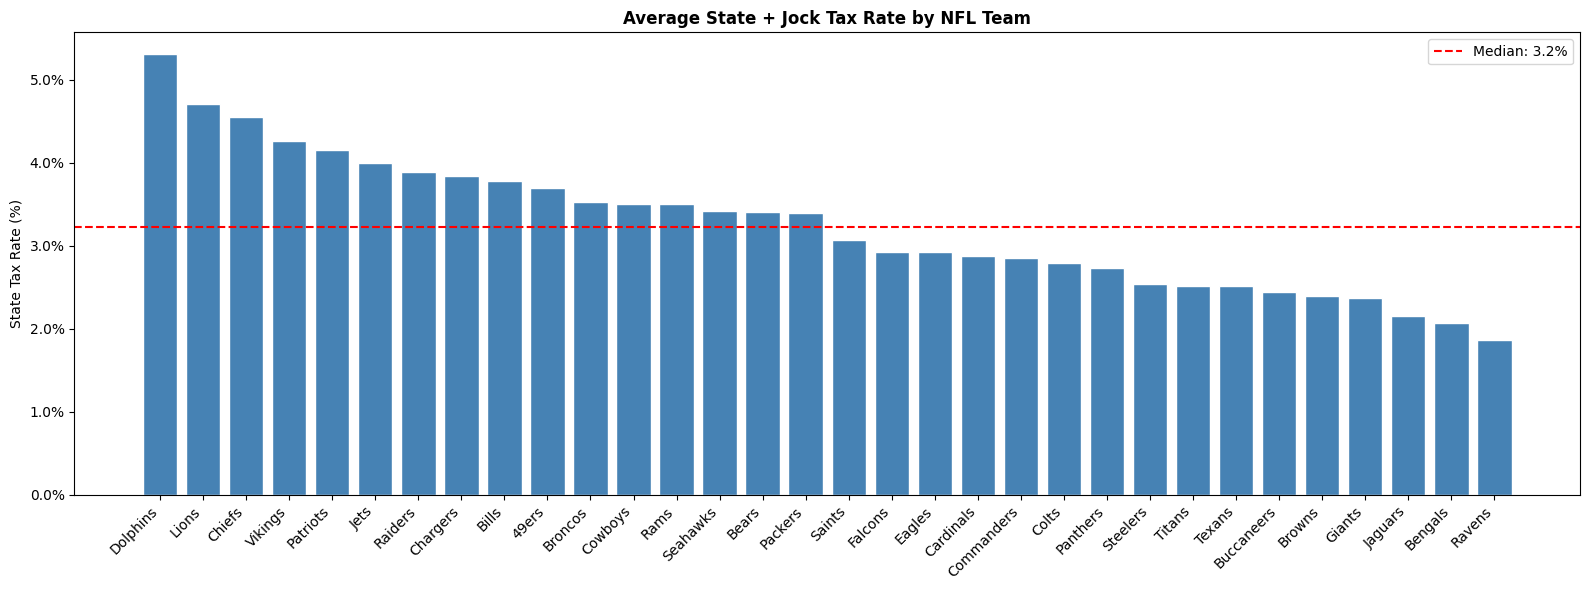

In [47]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

# State + Jock Tax
team_tax = (final_df.groupby('Team')['Home State Tax Rate'].mean() +
            final_df.groupby('Team')['Jock Tax Rate'].mean()) * 100
team_tax = team_tax.sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(16, 6))
ax.bar(team_tax.index, team_tax.values, color='steelblue', edgecolor='white')
ax.axhline(team_tax.median(), color='red', linestyle='--', label=f'Median: {team_tax.median():.1f}%')
ax.set_title('Average State + Jock Tax Rate by NFL Team', fontweight='bold')
ax.set_ylabel('State Tax Rate (%)')
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
plt.xticks(rotation=45, ha='right')
ax.legend()
plt.tight_layout()
plt.savefig('state_jock_tax.png')
plt.show()

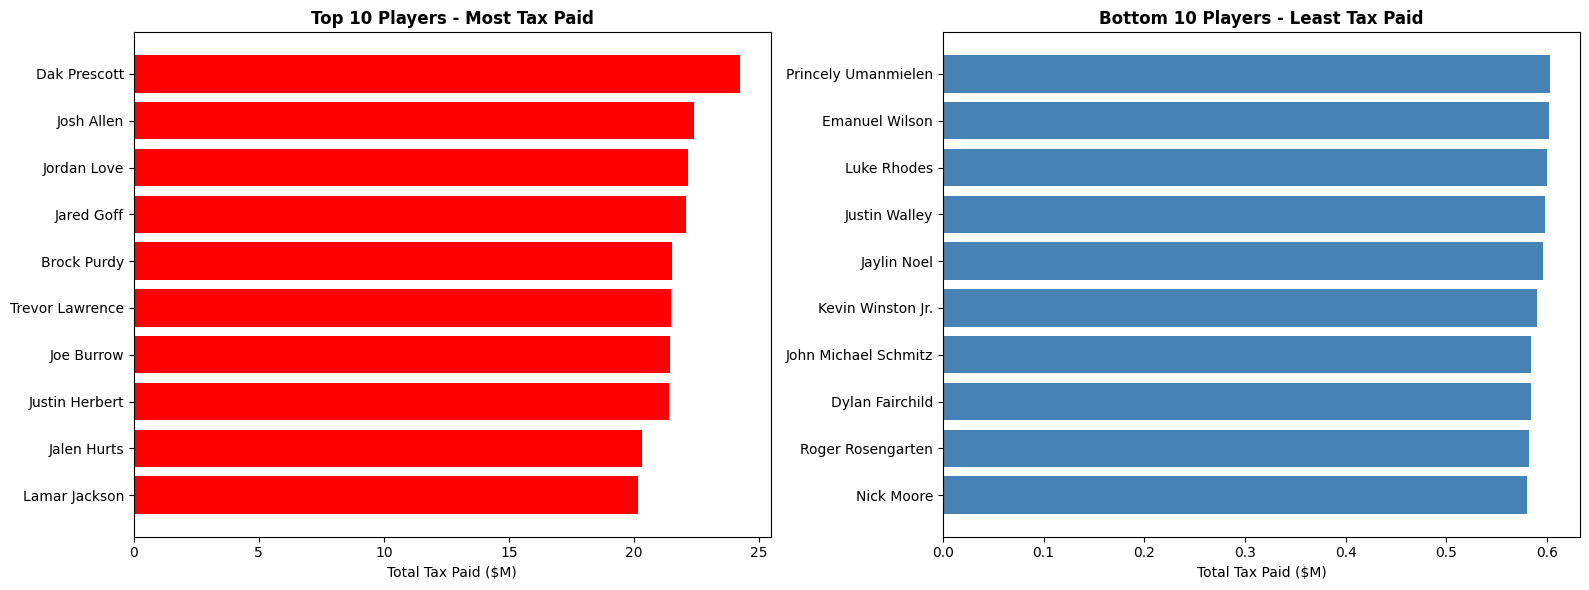

In [48]:
# top 10 and bottom 10 players by total tax dollars paid
sorted_players = final_df.dropna(subset=['Total Tax ($)']).sort_values('Total Tax ($)', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].barh(sorted_players.head(10)['Player'], sorted_players.head(10)['Total Tax ($)'] / 1_000_000, color='red')
axes[1].barh(sorted_players.tail(10)['Player'], sorted_players.tail(10)['Total Tax ($)'] / 1_000_000, color='steelblue')
axes[0].set_title('Top 10 Players - Most Tax Paid', fontweight='bold')
axes[1].set_title('Bottom 10 Players - Least Tax Paid', fontweight='bold')
for ax in axes:
    ax.set_xlabel('Total Tax Paid ($M)')
    ax.invert_yaxis()
plt.tight_layout()
plt.savefig('top_bottom_players.png')
plt.show()

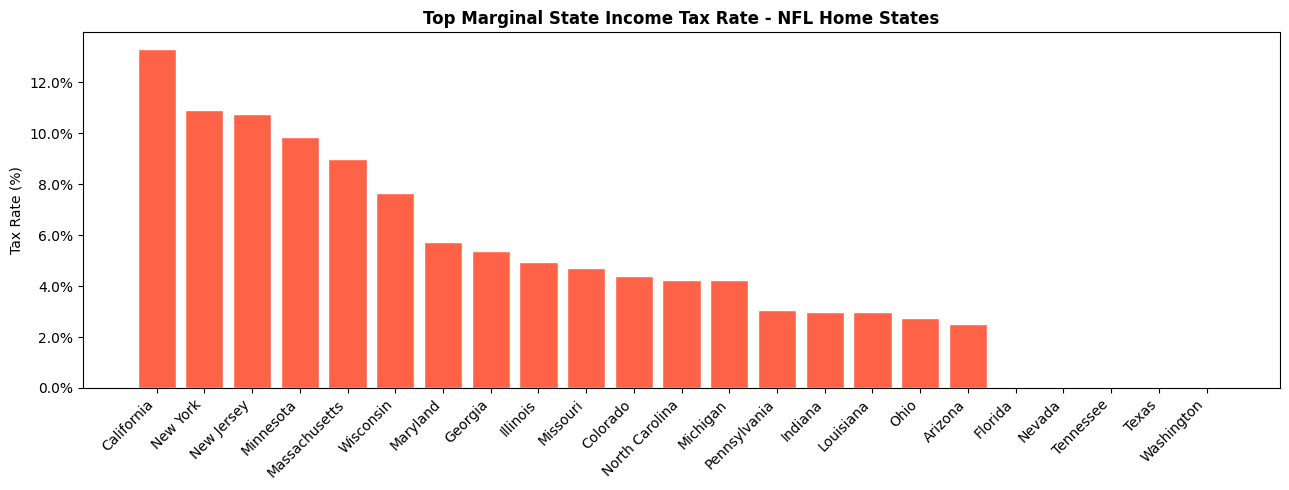

In [49]:
nfl_states = df_states['State'].unique()
state_rates_nfl = max_rates[max_rates['State'].isin(nfl_states)].sort_values('Rate', ascending=False)

fig, ax = plt.subplots(figsize=(13, 5))
colors = ['tomato' if r > 0 else 'lightgray' for r in state_rates_nfl['Rate']]
ax.bar(state_rates_nfl['State'], state_rates_nfl['Rate'], color=colors, edgecolor='white')
ax.set_title('Top Marginal State Income Tax Rate - NFL Home States', fontweight='bold')
ax.set_ylabel('Tax Rate (%)')
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('state_tax_rate.png')
plt.show()